In [ ]:
!pip install -q -U google-genai pymongo pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires google-auth==2.49.0, but you have google-auth 2.62.2 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
google-adk 2.7.1 requires google-genai<3,>=2.12.1, but you have google-genai 3.3.0 which is incompatible.


In [ ]:
!pip install -q "google-genai>=2.12.1,<3" "pandas==2.2.3" "google-auth==2.49.0" pymongo matplotlib

In [ ]:
import google.genai
import pymongo
import pandas
import matplotlib

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
from google.colab import userdata

GEMINI_API_KEY = userdata.get("GEMINI_API_KEY")

if not GEMINI_API_KEY:
    raise ValueError("Gemini API key is missing!")

print("Gemini API key configured successfully!")

Gemini API key configured successfully!


In [ ]:
from google import genai
from google.genai import types

client = genai.Client(
    api_key=GEMINI_API_KEY,
    http_options=types.HttpOptions(
        timeout=30000
    )
)

MODEL_NAME = "gemini-2.5-flash"

print("Gemini client initialized successfully!")

Gemini client initialized successfully!


In [ ]:
MODEL_NAME = "gemini-3.8-flash"

print("Model updated successfully:", MODEL_NAME)

Model updated successfully: gemini-3.8-flash


In [ ]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

ServerError: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}

In [ ]:
import time

for attempt in range(1, 4):
    try:
        response = client.models.generate_content(
            model=MODEL_NAME,
            contents="What is Artificial Intelligence?"
        )

        print(response.text)
        break

    except Exception as error:
        print(f"Attempt {attempt} failed: {error}")

        if attempt < 3:
            time.sleep(5)
        else:
            print("Gemini is still unavailable. Try again later.")

Attempt 1 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Attempt 2 failed: 503 UNAVAILABLE. {'error': {'code': 503, 'message': 'This model is currently experiencing high demand. Spikes in demand are usually temporary. Please try again later.', 'status': 'UNAVAILABLE'}}
Attempt 3 failed: 504 DEADLINE_EXCEEDED. {'error': {'code': 504, 'message': 'Deadline expired before operation could complete.', 'status': 'DEADLINE_EXCEEDED'}}
Gemini is still unavailable. Try again later.


In [ ]:
for model in client.models.list():
    if "generateContent" in (model.supported_actions or []):
        print(model.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/nano-banana-pro-preview
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-omni-1.2-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-4-carbon
models/gemi

In [ ]:
MODEL_NAME = "gemini-2.5-flash-lite"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

ClientError: 404 NOT_FOUND. {'error': {'code': 404, 'message': 'This model models/gemini-2.5-flash-lite is no longer available to new users. Please update your code to use models/gemini-3.5-flash-lite for the latest features and improvements. We recommend you to use the Interactions API (https://aistudio.google.com/docs/get-started).', 'status': 'NOT_FOUND'}}

In [ ]:
MODEL_NAME = "gemini-3.5-flash-lite"

response = client.models.generate_content(
    model=MODEL_NAME,
    contents="What is Artificial Intelligence?"
)

print(response.text)

**Artificial Intelligence (AI)** refers to the simulation of human intelligence in machines that are programmed to think, learn, adapt, and solve problems. 

In simpler terms, it is the broad science of making machines capable of performing tasks that typically require human cognition—such as reasoning, learning from experience, understanding language, recognizing patterns, and making decisions.

Here is a breakdown to help understand AI better:

---

### 1. How AI Works
Traditionally, computers need explicit, step-by-step instructions (programming) to do a job. AI, particularly **Machine Learning**, works differently. Instead of hard-coding rules, developers feed vast amounts of data into an algorithm and let the computer figure out the rules and patterns on its own. 

### 2. Key Subsets of AI
When people talk about AI, they are often referring to several overlapping technologies:
*   **Machine Learning (ML):** A subset of AI where computers use data and algorithms to "learn" and impr

In [ ]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

MONGODB_URI = userdata.get("MONGODB_URI")

if not MONGODB_URI:
    raise ValueError("MongoDB connection string is missing!")

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=5000,
    connectTimeoutMS=5000,
    socketTimeoutMS=10000,
    timeoutMS=10000,
    retryWrites=True
)

mongo_client.admin.command("ping")

db = mongo_client["GenAI_Monitoring"]

collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)

ServerSelectionTimeoutError: SSL handshake failed: ac-imgftg8-shard-00-02.yeurms0.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1035) (configured timeouts: socketTimeoutMS: 5000.0ms, connectTimeoutMS: 5000.0ms),SSL handshake failed: ac-imgftg8-shard-00-00.yeurms0.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1035) (configured timeouts: socketTimeoutMS: 5000.0ms, connectTimeoutMS: 5000.0ms),SSL handshake failed: ac-imgftg8-shard-00-01.yeurms0.mongodb.net:27017: [SSL: TLSV1_ALERT_INTERNAL_ERROR] tlsv1 alert internal error (_ssl.c:1035) (configured timeouts: socketTimeoutMS: 5000.0ms, connectTimeoutMS: 5000.0ms), Timeout: 9.999810805999914s, Topology Description: <TopologyDescription id: 6af6a39d054645282821690e, topology_type: ReplicaSetNoPrimary, servers: [<ServerDescription ('ac-imgftg8-shard-00-00.yeurms0.mongodb.net', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('SSL handshake failed: a

In [12]:
mongo_client.admin.command("ping")

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)

OperationFailure: bad auth : authentication failed, full error: {'ok': 0, 'errmsg': 'bad auth : authentication failed', 'code': 8000, 'codeName': 'AtlasError'}

In [13]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=15000
)

mongo_client.admin.command("ping")

db = mongo_client["GenAI_Monitoring"]
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Database:", db.name)
print("Collection:", collection.name)

ServerSelectionTimeoutError: deepsikha07:27017: [Errno -2] Name or service not known (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms), Timeout: 15.0s, Topology Description: <TopologyDescription id: 6af6a4e5054645282821690f, topology_type: Unknown, servers: [<ServerDescription ('deepsikha07', 27017) server_type: Unknown, rtt: None, error=AutoReconnect('deepsikha07:27017: [Errno -2] Name or service not known (configured timeouts: socketTimeoutMS: 20000.0ms, connectTimeoutMS: 20000.0ms)')>]>

In [14]:
from google.colab import userdata
from urllib.parse import urlparse

uri = userdata.get("MONGODB_URI")

parsed = urlparse(uri)

print("Connection scheme:", parsed.scheme)
print("Hostname:", parsed.hostname)
print("Username present:", bool(parsed.username))
print("Password present:", bool(parsed.password))

Connection scheme: mongodb+srv
Hostname: genaicluster.yeurms0.mongodb.net
Username present: True
Password present: True


In [15]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

# Close previous connection
try:
    mongo_client.close()
except:
    pass

# Get updated connection string
MONGODB_URI = userdata.get("MONGODB_URI")

# Create fresh connection
mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=20000
)

# Test connection
result = mongo_client.admin.command("ping")

db = mongo_client["GenAI_Monitoring"]
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")
print("Ping:", result["ok"])
print("Database:", db.name)
print("Collection:", collection.name)

OperationFailure: bad auth : authentication failed, full error: {'ok': 0, 'errmsg': 'bad auth : authentication failed', 'code': 8000, 'codeName': 'AtlasError'}

In [16]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=15000
)

print(mongo_client.admin.command("ping"))

db = mongo_client["GenAI_Monitoring"]
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")

OperationFailure: bad auth : authentication failed, full error: {'ok': 0, 'errmsg': 'bad auth : authentication failed', 'code': 8000, 'codeName': 'AtlasError'}

In [17]:
from pymongo import MongoClient
from pymongo.server_api import ServerApi
from google.colab import userdata

MONGODB_URI = userdata.get("MONGODB_URI")

mongo_client = MongoClient(
    MONGODB_URI,
    server_api=ServerApi("1"),
    serverSelectionTimeoutMS=15000
)

print(mongo_client.admin.command("ping"))

db = mongo_client["GenAI_Monitoring"]
collection = db["api_usage_logs"]

print("MongoDB connected successfully!")

{'ok': 1}
MongoDB connected successfully!


In [18]:
import time
import uuid
import random
import pymongo
import pandas as pd
import matplotlib.pyplot as plt

from datetime import datetime, timezone
from pymongo.errors import PyMongoError

print("All modules imported successfully!")

All modules imported successfully!


In [19]:
INPUT_PRICE = 0.30
OUTPUT_PRICE = 2.50

def calculate_cost(input_tokens, output_tokens):
    input_cost = (input_tokens / 1_000_000) * INPUT_PRICE
    output_cost = (output_tokens / 1_000_000) * OUTPUT_PRICE

    total_cost = input_cost + output_cost

    return round(total_cost, 8)

print("Token pricing configured successfully!")
print("Example cost:", calculate_cost(1000, 500))

Token pricing configured successfully!
Example cost: 0.00155


In [20]:
def retry_delay(attempt):
    delay = min(2 ** (attempt - 1), 16)
    return delay + random.uniform(0, 1)


def is_temporary_error(error):
    status_code = getattr(
        error,
        "status_code",
        getattr(error, "code", None)
    )

    if status_code in [408, 429, 500, 502, 503, 504]:
        return True

    error_name = type(error).__name__.lower()

    temporary_errors = [
        "timeout",
        "connection",
        "temporarily"
    ]

    return any(word in error_name for word in temporary_errors)


print("Automatic retry logic configured successfully!")

Automatic retry logic configured successfully!


In [21]:
def save_log(log_data, max_retries=3):

    for attempt in range(1, max_retries + 1):
        try:
            collection.update_one(
                {"log_id": log_data["log_id"]},
                {"$setOnInsert": log_data},
                upsert=True
            )

            print("Log saved successfully!")
            return True

        except PyMongoError as error:
            print(f"Logging attempt {attempt} failed: {error}")

            if attempt < max_retries:
                time.sleep(retry_delay(attempt))

    print("Failed to save log after retries.")
    return False


print("MongoDB logging function created successfully!")

MongoDB logging function created successfully!


In [22]:

def ask_gemini(prompt, max_attempts=4):

    for attempt in range(1, max_attempts + 1):

        log_id = str(uuid.uuid4())
        start_time = time.perf_counter()

        try:
            response = client.models.generate_content(
                model=MODEL_NAME,
                contents=prompt
            )

            latency = round(time.perf_counter() - start_time, 3)

            usage = response.usage_metadata

            input_tokens = usage.prompt_token_count or 0
            output_tokens = usage.candidates_token_count or 0
            total_tokens = usage.total_token_count or 0

            cost = calculate_cost(input_tokens, output_tokens)

            log_data = {
                "log_id": log_id,
                "timestamp": datetime.now(timezone.utc),
                "prompt": prompt,
                "input_tokens": input_tokens,
                "output_tokens": output_tokens,
                "total_tokens": total_tokens,
                "latency": latency,
                "estimated_cost": cost,
                "status": "SUCCESS",
                "retry_attempt": attempt
            }

            save_log(log_data)

            print(f"Attempt: {attempt}")
            print(f"Latency: {latency} seconds")
            print(f"Input tokens: {input_tokens}")
            print(f"Output tokens: {output_tokens}")
            print(f"Total tokens: {total_tokens}")
            print(f"Estimated cost: ${cost}")

            return response.text

        except Exception as error:

            latency = round(time.perf_counter() - start_time, 3)

            log_data = {
                "log_id": log_id,
                "timestamp": datetime.now(timezone.utc),
                "prompt": prompt,
                "input_tokens": 0,
                "output_tokens": 0,
                "total_tokens": 0,
                "latency": latency,
                "estimated_cost": 0,
                "status": "FAILED",
                "retry_attempt": attempt,
                "error": str(error)
            }

            save_log(log_data)

            print(f"Attempt {attempt} failed: {error}")

            if attempt == max_attempts or not is_temporary_error(error):
                print("Gemini API request failed.")
                return None

            delay = retry_delay(attempt)
            print(f"Retrying in {delay:.2f} seconds...")
            time.sleep(delay)


In [23]:
prompt = "Explain Artificial Intelligence in simple words with 3 examples."

response_text = ask_gemini(prompt)

print("\nGemini Response:\n")
print(response_text)

Log saved successfully!
Attempt: 1
Latency: 2.315 seconds
Input tokens: 12
Output tokens: 365
Total tokens: 377
Estimated cost: $0.0009161

Gemini Response:

Imagine teaching a computer to think, learn, and make decisions a bit like a human. That is **Artificial Intelligence (AI)**. 

Instead of just following strict step-by-step instructions, an AI system looks at lots of information (data), spots patterns, and figures out how to solve problems on its own.

Here are 3 simple examples of AI you probably use every day:

### 1. Recommendation Systems (like Netflix or Spotify)
Have you ever noticed how Netflix always seems to know what movie you want to watch next, or Spotify recommends songs you love? 
* **How AI does it:** The AI watches what you watch, listens to what you skip, and looks at what millions of other people with similar tastes enjoy. It learns your preferences and uses that information to make smart guesses about what you will like next.

### 2. Smartphone Face Unlock
When

In [24]:
logs = list(
    collection.find().sort("timestamp", -1).limit(10)
)

print("Total logs retrieved:", len(logs))

for log in logs:
    print("\n----------------------------")
    print("Log ID:", log.get("log_id"))
    print("Status:", log.get("status"))
    print("Input Tokens:", log.get("input_tokens"))
    print("Output Tokens:", log.get("output_tokens"))
    print("Total Tokens:", log.get("total_tokens"))
    print("Latency:", log.get("latency"))
    print("Estimated Cost:", log.get("estimated_cost"))
    print("Retry Attempt:", log.get("retry_attempt"))

Total logs retrieved: 1

----------------------------
Log ID: 54e4beca-dbbe-42fa-b0dc-d38250a3b17c
Status: SUCCESS
Input Tokens: 12
Output Tokens: 365
Total Tokens: 377
Latency: 2.315
Estimated Cost: 0.0009161
Retry Attempt: 1


In [25]:
logs = list(collection.find({}, {"_id": 0}))

df = pd.DataFrame(logs)

if not df.empty:
    display(df)
else:
    print("No API logs found.")

,log_id,estimated_cost,input_tokens,latency,output_tokens,prompt,retry_attempt,status,timestamp,total_tokens
0,54e4beca-dbbe-42fa-b0dc-d38250a3b17c,0.000916,12,2.315,365,Explain Artificial Intelligence in simple word...,1,SUCCESS,2026-11-13 05:58:49.456,377


In [26]:
pipeline = [
    {
        "$group": {
            "_id": "$status",
            "total_requests": {"$sum": 1},
            "total_input_tokens": {"$sum": "$input_tokens"},
            "total_output_tokens": {"$sum": "$output_tokens"},
            "total_tokens": {"$sum": "$total_tokens"},
            "average_latency": {"$avg": "$latency"},
            "total_cost": {"$sum": "$estimated_cost"}
        }
    }
]

results = list(collection.aggregate(pipeline))

for result in results:
    print("\nStatus:", result["_id"])
    print("Total Requests:", result["total_requests"])
    print("Input Tokens:", result["total_input_tokens"])
    print("Output Tokens:", result["total_output_tokens"])
    print("Total Tokens:", result["total_tokens"])
    print("Average Latency:", round(result["average_latency"], 3))
    print("Total Cost: $", round(result["total_cost"], 8))


Status: SUCCESS
Total Requests: 1
Input Tokens: 12
Output Tokens: 365
Total Tokens: 377
Average Latency: 2.315
Total Cost: $ 0.0009161


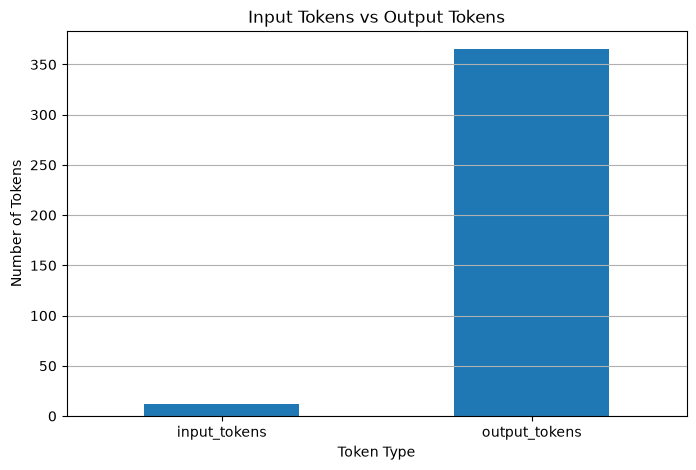

In [27]:
if not df.empty:
    token_data = df[["input_tokens", "output_tokens"]].sum()

    plt.figure(figsize=(8, 5))
    token_data.plot(kind="bar")

    plt.title("Input Tokens vs Output Tokens")
    plt.xlabel("Token Type")
    plt.ylabel("Number of Tokens")
    plt.xticks(rotation=0)
    plt.grid(axis="y")
    plt.show()
else:
    print("No data available for visualization.")

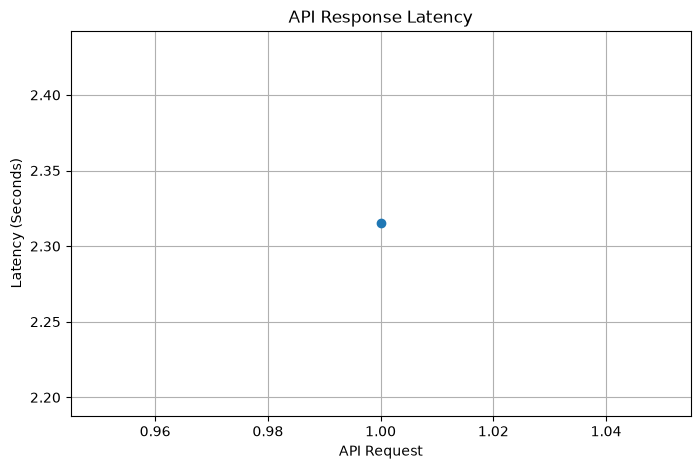

In [28]:
if not df.empty:
    plt.figure(figsize=(8, 5))

    plt.plot(
        range(1, len(df) + 1),
        df["latency"],
        marker="o"
    )

    plt.title("API Response Latency")
    plt.xlabel("API Request")
    plt.ylabel("Latency (Seconds)")
    plt.grid(True)
    plt.show()
else:
    print("No data available for visualization.")

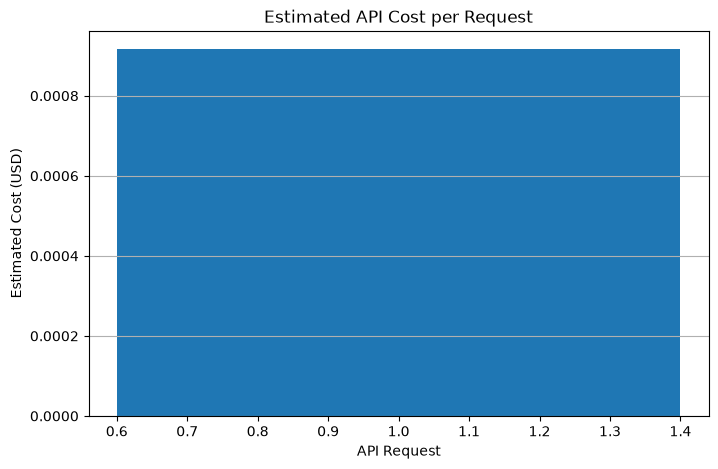

In [29]:
if not df.empty:
    plt.figure(figsize=(8, 5))

    plt.bar(
        range(1, len(df) + 1),
        df["estimated_cost"]
    )

    plt.title("Estimated API Cost per Request")
    plt.xlabel("API Request")
    plt.ylabel("Estimated Cost (USD)")
    plt.grid(axis="y")
    plt.show()
else:
    print("No data available for visualization.")